In [7]:
import pandas as pd
import numpy as np

CSV_PATH = "../data/NEW_NBE_and_NBI_OK.csv"
TARGET_COL = "HI"
YEAR_COL = "YEAR"
BRIDGE_ID_COL = "STRUCTURE_NUMBER"
ELEM_NUM_COL = "ELEMENT_NUMBER"
PARENT_ELEM_NUM_COL = "PARENT_ELEMENT_NUMBER"

YEARS = [2020, 2021, 2022, 2023, 2024]

def normalize_bridge_id(x) -> str:
    """
    STRUCTURE_NUMBER loads as float sometimes (e.g., 5550000000000.0).
    Convert to a stable string ID without losing precision.
    """
    if pd.isna(x):
        return None
    # Use integer-string if possible
    try:
        return str(int(float(x)))
    except Exception:
        return str(x)

def build_global_node_index(df: pd.DataFrame):
    """
    Creates a global node index across all years:
      - bridge:{bridge_id}
      - elem:{bridge_id}:{element_number}
    Returns:
      node2idx: dict[str, int]
      idx2node: list[str]
      elem_nodes: set[str]  (node keys for elements)
      bridge_nodes: set[str]
    """
    bridge_ids = df[BRIDGE_ID_COL].map(normalize_bridge_id)
    elem_nums = df[ELEM_NUM_COL].astype("Int64")

    bridge_nodes = set(f"bridge:{bid}" for bid in bridge_ids.dropna().unique())
    elem_nodes = set(
        f"elem:{bid}:{int(en)}"
        for bid, en in zip(bridge_ids, elem_nums)
        if (bid is not None) and (not pd.isna(en))
    )

    all_nodes = sorted(list(bridge_nodes | elem_nodes))
    node2idx = {k: i for i, k in enumerate(all_nodes)}
    return node2idx, all_nodes, elem_nodes, bridge_nodes

def build_static_edges(df: pd.DataFrame, node2idx: dict):
    """
    Builds a static edge_index (2, E) with:
      - bridge <-> element edges
      - parent_element -> element edges (and reverse)
    """
    edges = []

    b_ids = df[BRIDGE_ID_COL].map(normalize_bridge_id).values
    e_nums = df[ELEM_NUM_COL].astype("Int64").values
    p_nums = df[PARENT_ELEM_NUM_COL].astype("Int64").values

    for bid, en, pn in zip(b_ids, e_nums, p_nums):
        if bid is None or pd.isna(en):
            continue

        b_key = f"bridge:{bid}"
        e_key = f"elem:{bid}:{int(en)}"

        if b_key in node2idx and e_key in node2idx:
            b_i = node2idx[b_key]
            e_i = node2idx[e_key]
            # undirected / bidirectional
            edges.append((b_i, e_i))
            edges.append((e_i, b_i))

        # parent-child within same bridge if parent exists as element node
        if not pd.isna(pn):
            p_key = f"elem:{bid}:{int(pn)}"
            if p_key in node2idx and e_key in node2idx:
                p_i = node2idx[p_key]
                e_i = node2idx[e_key]
                edges.append((p_i, e_i))
                edges.append((e_i, p_i))

    # de-duplicate
    edges = list(set(edges))
    edge_index = np.array(edges, dtype=np.int64).T  # shape (2, E)
    return edge_index

def make_feature_frame(df: pd.DataFrame):
    """
    Creates a feature-ready dataframe:
      - converts booleans to 0/1
      - one-hot encodes remaining object/categorical columns (except IDs)
      - keeps numeric columns as-is
    IMPORTANT: we will remove leakage columns later (like TARGET, YEAR, IDs).
    """
    work = df.copy()

    # bool -> int
    bool_cols = [c for c in work.columns if work[c].dtype == bool]
    for c in bool_cols:
        work[c] = work[c].astype(np.int8)

    # Identify columns we do NOT want to one-hot
    id_like = {YEAR_COL, BRIDGE_ID_COL, "LATEST_STRUCTURE_NUMBER", "NBI_8 - Structure Number", "NBI_2025 NBI Structure Number"}
    # Keep element numbers numeric as-is (or you can drop them later)
    # We'll one-hot encode remaining object columns that aren’t IDs.
    obj_cols = [c for c in work.columns if work[c].dtype == "object" and c not in id_like]

    # One-hot encode object columns (can get large; but preserves info)
    work = pd.get_dummies(work, columns=obj_cols, dummy_na=True)

    # -----------------------------------------------
    work = work.apply(pd.to_numeric, errors="coerce")
    work = work.replace([np.inf, -np.inf], np.nan)
    work = work.fillna(0.0)
    # -----------------------------------------------

    return work

def build_yearly_matrices(df_raw: pd.DataFrame, node2idx: dict, elem_nodes: set, bridge_nodes: set):
    """
    Returns:
      X_list: list[np.ndarray] of shape (N, F)
      y_list: list[np.ndarray] of shape (N,) with NaN for non-element nodes or missing labels
      label_mask_list: list[np.ndarray] boolean mask for supervised nodes each year
      feature_cols: list[str]
    """
    df = df_raw.copy()
    df[BRIDGE_ID_COL] = df[BRIDGE_ID_COL].map(normalize_bridge_id)

    feat_df = make_feature_frame(df)

    # Drop leakage / identifiers from features
    drop_cols = [
        TARGET_COL, YEAR_COL, BRIDGE_ID_COL,
        "LATEST_STRUCTURE_NUMBER", "NBI_8 - Structure Number", "NBI_2025 NBI Structure Number"
    ]
    drop_cols = [c for c in drop_cols if c in feat_df.columns]
    feat_df_no_leak = feat_df.drop(columns=drop_cols)

    feature_cols = list(feat_df_no_leak.columns)
    N = len(node2idx)
    F = len(feature_cols)

    X_list, y_list, mask_list = [], [], []

    # Precompute node-type indicator (helps a lot in mixed node graphs)
    node_type = np.zeros((N, 2), dtype=np.float32)  # [is_bridge, is_element]
    for k, i in node2idx.items():
        if k.startswith("bridge:"):
            node_type[i, 0] = 1.0
        else:
            node_type[i, 1] = 1.0

    for year in YEARS:
        sub_raw = df[df[YEAR_COL] == year]
        sub_feat = feat_df_no_leak.loc[sub_raw.index]

        X = np.zeros((N, F + 2), dtype=np.float32)  # +2 for node type
        y = np.full((N,), np.nan, dtype=np.float32)

        # Fill element-node features row-by-row (this keeps everything)
        for ridx, row in sub_raw.iterrows():
            bid = row[BRIDGE_ID_COL]
            en = row[ELEM_NUM_COL]
            if pd.isna(bid) or pd.isna(en):
                continue

            e_key = f"elem:{bid}:{int(en)}"
            if e_key not in node2idx:
                continue
            ni = node2idx[e_key]

            X[ni, :F] = sub_feat.loc[ridx].to_numpy(dtype=np.float32, copy=False)
            # target label for this year (HI)
            if TARGET_COL in sub_raw.columns and not pd.isna(row[TARGET_COL]):
                y[ni] = float(row[TARGET_COL])

            # Bridge node features: you can optionally ALSO fill the bridge node by aggregating
            # one row per bridge-year. A simple way:
            # - pick first row of that bridge-year to populate the bridge node (since NBI fields repeat)
            # We'll do that after loop to avoid repeated assignments.

        # Populate bridge nodes using the first row per bridge in this year
        first_per_bridge = sub_raw.dropna(subset=[BRIDGE_ID_COL]).groupby(BRIDGE_ID_COL).head(1)
        for ridx, row in first_per_bridge.iterrows():
            bid = row[BRIDGE_ID_COL]
            b_key = f"bridge:{bid}"
            if b_key not in node2idx:
                continue
            bi = node2idx[b_key]
            X[bi, :F] = sub_feat.loc[ridx].to_numpy(dtype=np.float32, copy=False)

        # append node type indicator
        X[:, F:] = node_type

        # Mask: supervised nodes are element nodes with non-NaN y
        label_mask = ~np.isnan(y)

        X_list.append(X)
        y_list.append(y)
        mask_list.append(label_mask)

    return X_list, y_list, mask_list, feature_cols

In [8]:
import numpy as np

def add_hi_prev_feature(X_list, y_list):
    """
    Appends 1 feature column to every X_t:
      HI_prev at time t (ground truth during training)
    For t=0 (2020), HI_prev = HI_2020
    """
    X_ar = []
    for t in range(len(X_list)):
        X = X_list[t]
        hi_prev = y_list[t].copy()  # (N,)
        hi_prev = np.nan_to_num(hi_prev, nan=0.0).astype(np.float32)

        # normalize to 0..1
        hi_prev_norm = (hi_prev / 100.0).astype(np.float32)

        X_new = np.concatenate([X, hi_prev_norm[:, None]], axis=1)  # (N, F+1)
        X_ar.append(X_new)
    return X_ar

X_list_ar = add_hi_prev_feature(X_list, y_list)
print("Old dim:", X_list[0].shape, "New dim:", X_list_ar[0].shape)

NameError: name 'X_list' is not defined

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class TemporalGCN_GRU(nn.Module):
    def __init__(self, in_dim: int, gcn_hidden: int = 128, gru_hidden: int = 128):
        super().__init__()
        self.gcn1 = GCNConv(in_dim, gcn_hidden)
        self.gcn2 = GCNConv(gcn_hidden, gcn_hidden)
        self.gru = nn.GRU(input_size=gcn_hidden, hidden_size=gru_hidden, batch_first=False)
        self.head = nn.Linear(gru_hidden, 1)

    def forward(self, X_seq, edge_index):
        embeddings = []
        for X in X_seq:
            h = F.relu(self.gcn1(X, edge_index))
            h = F.relu(self.gcn2(h, edge_index))
            embeddings.append(h)

        H = torch.stack(embeddings, dim=0)  # (T, N, H)
        out, _ = self.gru(H)                # (T, N, gru_hidden)

        logits = self.head(out).squeeze(-1) # (T, N)
        preds = torch.sigmoid(logits)       # (T, N) in 0..1

        return preds[:-1]                   # (T-1, N) predicts next step
        return preds_next

c:\Users\clnnaLAB\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
def train_with_temporal_split(model, X_list, y_list, mask_list, edge_index, lr=1e-3, epochs=120):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)
    X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list]

    # normalize targets to 0..1
    y_seq = [torch.tensor(np.nan_to_num(y, nan=np.nan), dtype=torch.float32, device=device) / 100.0 for y in y_list]
    m_seq = [torch.tensor(m, dtype=torch.bool, device=device) for m in mask_list]

    # Split: train on transitions 2020->2021, 2021->2022, 2022->2023 (t=0,1,2)
    train_ts = [0, 1, 2]
    test_t = 3  # 2023->2024

    opt = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(1, epochs + 1):
        model.train()
        opt.zero_grad()

        preds_next = model(X_seq, edge_index_t)  # (T-1, N)

        train_losses = []
        for t in train_ts:
            mask = m_seq[t + 1]
            if mask.sum() == 0:
                continue
            y_true = y_seq[t + 1]
            train_losses.append(F.smooth_l1_loss(preds_next[t][mask], y_true[mask]))

        loss = torch.stack(train_losses).mean()
        loss.backward()
        opt.step()

        if ep % 20 == 0:
            model.eval()
            with torch.no_grad():
                mask = m_seq[test_t + 1]
                y_true = y_seq[test_t + 1]
                test_loss = F.smooth_l1_loss(preds_next[test_t][mask], y_true[mask]).item()
            print(f"epoch {ep:04d} | train {loss.item():.5f} | test {test_loss:.5f}")

    return model

In [11]:
#def train_one_step(model, X_list, y_list, mask_list, edge_index, lr=1e-3, epochs=200):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)
    X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list]
    y_seq = [torch.tensor(y, dtype=torch.float32, device=device) for y in y_list]
    m_seq = [torch.tensor(m, dtype=torch.bool, device=device) for m in mask_list]

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()

        preds_next = model(X_seq, edge_index_t)  # (T-1, N)

        losses = []
        for t in range(len(X_seq) - 1):
            y_true = y_seq[t + 1]
            mask = m_seq[t + 1]

            if mask.sum() == 0:
                continue  # avoid empty-loss NaN

            loss = F.smooth_l1_loss(preds_next[t][mask], y_true[mask])
            losses.append(loss)

        if len(losses) == 0:
            raise RuntimeError("No supervised labels found in any timestep (all masks empty).")

        loss_total = torch.stack(losses).mean()

        if torch.isnan(loss_total):
            raise RuntimeError("Loss is NaN. Check for NaNs/Infs in X or y.")

        loss_total.backward()
        optimizer.step()

        if ep % 20 == 0:
            print(f"epoch {ep:04d} | loss {loss_total.item():.5f}")

    return model

IndentationError: unexpected indent (2829694912.py, line 2)

In [42]:
@torch.no_grad()
def rollout_autoregressive(model, X_list_ar, edge_index, years_ahead=5):
    device = next(model.parameters()).device
    edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)

    X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list_ar]
    last_X = X_seq[-1].clone()

    preds_future = []

    for _ in range(years_ahead):
        preds_next = model(X_seq, edge_index_t)   # (T-1, N) in 0..1
        y_hat_next = preds_next[-1]               # next-year prediction (0..1)

        preds_future.append((y_hat_next * 100.0).detach().cpu().numpy())  # back to 0..100

        # Update HI_prev feature in last_X (last column)
        last_X[:, -1] = y_hat_next

        # Slide window
        X_seq = X_seq[1:] + [last_X.clone()]

    return preds_future

In [43]:
df_raw = pd.read_csv(CSV_PATH, low_memory=False)

node2idx, idx2node, elem_nodes, bridge_nodes = build_global_node_index(df_raw)
edge_index = build_static_edges(df_raw, node2idx)

X_list, y_list, mask_list, feature_cols = build_yearly_matrices(df_raw, node2idx, elem_nodes, bridge_nodes)

print("Nodes:", len(node2idx), "Edges:", edge_index.shape[1])
print("Snapshots:", len(X_list), "X0:", X_list[0].shape, "labels0:", mask_list[0].sum())

Nodes: 24066 Edges: 47204
Snapshots: 5 X0: (24066, 4700) labels0: 18788


In [44]:
import torch

model = TemporalGCN_GRU(in_dim=X_list_ar[0].shape[1], gcn_hidden=64, gru_hidden=64)
model = train_with_temporal_split(model, X_list_ar, y_list, mask_list, edge_index, lr=1e-3, epochs=120)

# Save model weights
torch.save(model.state_dict(), "../models/temporal_gnn_bridge_hi.pt")
print("Saved temporal_gnn_bridge_hi.pt")

epoch 0020 | train 0.02003 | test 0.01868
epoch 0040 | train 0.01871 | test 0.01779
epoch 0060 | train 0.01719 | test 0.01688
epoch 0080 | train 0.01609 | test 0.01616
epoch 0100 | train 0.01578 | test 0.01597
epoch 0120 | train 0.01476 | test 0.01498
Saved temporal_gnn_bridge_hi.pt


In [45]:
# Predict HI for 2025..2029 (baseline: repeat 2024 features)
preds_future = rollout_autoregressive(model, X_list_ar, edge_index, years_ahead=5)
# Build a mapping from node index -> (bridge_id, element_number)
elem_rows = []
for node_key, idx in node2idx.items():
    if node_key.startswith("elem:"):
        # node_key format: elem:{bridge}:{element}
        _, bid, en = node_key.split(":")
        elem_rows.append((idx, bid, int(en)))

elem_map = pd.DataFrame(elem_rows, columns=["node_idx", "STRUCTURE_NUMBER", "ELEMENT_NUMBER"])

# Convert predictions into a long table
out = elem_map.copy()
for i, year in enumerate([2025, 2026, 2027, 2028, 2029]):
    out[f"HI_pred_{year}"] = preds_future[i][out["node_idx"].to_numpy()]

out.to_csv("../results/element_hi_forecast_2025_2029.csv", index=False)
print("Saved element_hi_forecast_2025_2029.csv")
out.head()

Saved element_hi_forecast_2025_2029.csv


,node_idx,STRUCTURE_NUMBER,ELEMENT_NUMBER,HI_pred_2025,HI_pred_2026,HI_pred_2027,HI_pred_2028,HI_pred_2029
0,3128,103420000000000,109,72.531769,72.521118,72.520775,72.521194,72.360252
1,3129,103420000000000,110,73.352226,72.606987,72.520355,72.520828,72.358337
2,3130,103420000000000,12,72.035446,71.964798,67.665527,67.665527,67.665527
3,3131,103420000000000,202,72.517685,72.507439,72.316658,72.344574,71.810326
4,3132,103420000000000,205,72.899887,72.540337,72.515076,72.517639,72.081505


In [46]:
bridge_risk = out.groupby("STRUCTURE_NUMBER")["HI_pred_2029"].min().sort_values()
bridge_risk.head(25)

STRUCTURE_NUMBER
179570000000000    57.403118
257550000000000    58.419182
266580000000000    58.420872
139210000000000    58.727657
213450000000000    59.393345
181470000000000    59.393353
161670000000000    59.393353
179580000000000    59.393406
211120000000000    59.538353
161590000000000    59.811489
192670000000000    61.476917
173360000000000    61.497299
128290000000000    62.156914
181390000000000    62.376137
157940000000000    62.391163
94980000000000     62.428486
95080000000000     62.486614
208190000000000    62.616245
220960000000000    62.859177
173590000000000    62.877102
176090000000000    62.995464
200040000000000    63.135574
136880000000000    63.143902
179010000000000    63.157963
220990000000000    63.460014
Name: HI_pred_2029, dtype: float32

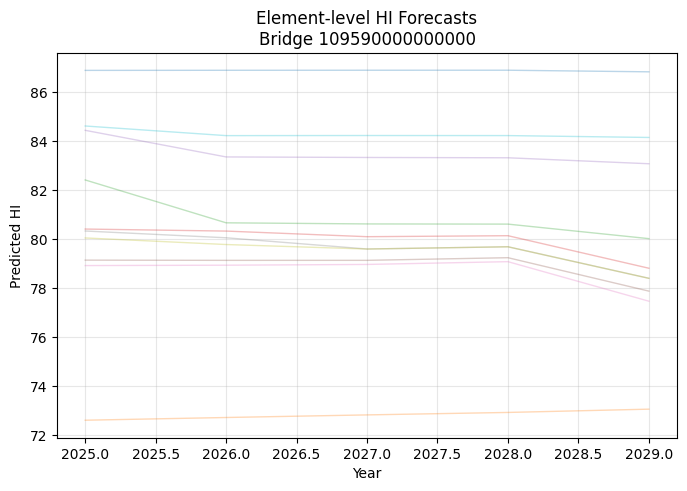

In [50]:
import matplotlib.pyplot as plt
import numpy as np

bridge_id = out["STRUCTURE_NUMBER"].iloc[100]
sub = out[out["STRUCTURE_NUMBER"] == bridge_id].copy()

years = np.array([2025, 2026, 2027, 2028, 2029])

plt.figure(figsize=(8, 5))
for _, r in sub.iterrows():
    plt.plot(
        years,
        [r[f"HI_pred_{y}"] for y in years],
        alpha=0.3,
        linewidth=1
    )

plt.title(f"Element-level HI Forecasts\nBridge {bridge_id}")
plt.xlabel("Year")
plt.ylabel("Predicted HI")
plt.grid(True, alpha=0.3)
plt.show()

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device).eval()

edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)
X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list_ar]

with torch.no_grad():
    preds_next = model(X_seq, edge_index_t)  # (T-1, N) in 0..1
    pred_2024 = preds_next[3].detach().cpu().numpy() * 100.0  # 2023->2024 is t=3
    true_2024 = y_list[4]  # year index 4 is 2024
    mask_2024 = mask_list[4]

yhat = pred_2024[mask_2024]
ytrue = true_2024[mask_2024]

mae = np.mean(np.abs(yhat - ytrue))
rmse = np.sqrt(np.mean((yhat - ytrue) ** 2))

print(f"Test (2023->2024) MAE:  {mae:.3f} HI points")
print(f"Test (2023->2024) RMSE: {rmse:.3f} HI points")
print("Pred range:", (float(yhat.min()), float(yhat.max())))
print("True range:", (float(ytrue.min()), float(ytrue.max())))

plt.figure(figsize=(6, 6))
plt.scatter(ytrue, yhat, s=3, alpha=0.3)
lo = min(ytrue.min(), yhat.min())
hi = max(ytrue.max(), yhat.max())
plt.plot([lo, hi], [lo, hi])  # y=x
plt.title("Held-out Test: Predict 2024 HI from 2023 Inputs")
plt.xlabel("Actual HI (2024)")
plt.ylabel("Predicted HI (2024)")
plt.grid(True, alpha=0.3)
plt.show()

NameError: name 'model' is not defined